# 06 - Text + Image Fusion

Goal: combine the text and image models and check if this beats text alone.

1. Turn the text SVM scores into probabilities.
2. Match text and image probabilities on the same 16984 validation products.
3. Compare three ways to combine them:
   - **Simple fusion:** a weighted average, with one fixed weight for text and image.
   - **Random Forest** (bagging): many decision trees trained on random samples, which then vote.
   - **Gradient Boosting** (boosting): trees trained one after another, each one fixing the errors of the previous ones.

Random Forest and Gradient Boosting learn how to combine the two models. Their input is, for each product, the 27 text probabilities and the 27 image probabilities (54 numbers).

Finally, we add the CamemBERT text model (notebook 05) as a third input.


## 1. Text probabilities

We use the optimised text model from notebook 04 (all features, binary TF-IDF, LinearSVC with C = 1). A LinearSVC gives scores, not probabilities. Calibration learns on the training set (3-fold CV) how to turn these scores into probabilities.

In [1]:
import matplotlib.pyplot as plt
import time

import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC

from src.categories import CATEGORY_NAMES
from src.metrics import compute_per_class_metrics

data = pd.read_csv("../data/processed/text_train_processed.csv")
train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
X_train = vectorizer.fit_transform(train["text_combined"])
X_validation = vectorizer.transform(validation["text_combined"])

# Optimised LinearSVC from notebook 04, wrapped to output probabilities
text_model = CalibratedClassifierCV(LinearSVC(C=1, random_state=42), cv=3)
text_model.fit(X_train, train["prdtypecode"])
classes = text_model.classes_

text_probs = pd.DataFrame(text_model.predict_proba(X_validation), columns=classes)
text_probs.insert(0, "row_id", validation["row_id"].to_numpy())
text_probs.to_csv("../data/processed/text_validation_probabilities.csv", index=False)

print(f"Text probabilities saved: {text_probs.shape}")
print(f"Each row sums to 1: {np.allclose(text_probs[classes].sum(axis=1), 1)}")

Text probabilities saved: (16984, 28)
Each row sums to 1: True


## 2. Match text and image on the same products

In [2]:
image = pd.read_csv("../data/processed/image_validation_predictions.csv")
image_probs = image[["row_id"] + [f"prob_{c}" for c in classes]]
image_probs.columns = ["row_id"] + list(classes)

both = (
    validation[["row_id", "prdtypecode"]]
    .merge(text_probs, on="row_id")
    .merge(image_probs, on="row_id", suffixes=("_text", "_image"))
)
y_true = both["prdtypecode"].to_numpy()
P_text = both[[f"{c}_text" for c in classes]].to_numpy()
P_image = both[[f"{c}_image" for c in classes]].to_numpy()

print(f"Products scored by both: {len(both)}")

Products scored by both: 16984


## 3. Compare the three ways to combine

Text and image probabilities exist for the 16984 validation products, which neither model was trained on. We score every method with 5-fold cross-validation on these products: the combiner learns on 4/5 of them and predicts the remaining 1/5. Every product is predicted by a combiner that never saw it.

For simple fusion, the text weight (0 to 1, in steps of 0.1) is chosen on the 4/5 part only, in the same way.

In [3]:
X = np.hstack([P_text, P_image])
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
weights = np.round(np.arange(0, 1.01, 0.1), 1)

predictions = {name: np.zeros_like(y_true) for name in ["Simple fusion", "Random Forest", "Gradient Boosting"]}
times = {"Random Forest": 0.0, "Gradient Boosting": 0.0}
chosen_weights = []

for train_idx, test_idx in folds.split(X, y_true):
    # Simple fusion: choose the text weight on the training part only
    fold_scores = [
        f1_score(y_true[train_idx], classes[(w * P_text[train_idx] + (1 - w) * P_image[train_idx]).argmax(axis=1)], average="weighted")
        for w in weights
    ]
    best_w = weights[int(np.argmax(fold_scores))]
    chosen_weights.append(float(best_w))
    predictions["Simple fusion"][test_idx] = classes[(best_w * P_text[test_idx] + (1 - best_w) * P_image[test_idx]).argmax(axis=1)]

    start = time.time()
    forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42)
    predictions["Random Forest"][test_idx] = forest.fit(X[train_idx], y_true[train_idx]).predict(X[test_idx])
    times["Random Forest"] += time.time() - start

    start = time.time()
    boosting = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, early_stopping=True, random_state=42)
    predictions["Gradient Boosting"][test_idx] = boosting.fit(X[train_idx], y_true[train_idx]).predict(X[test_idx])
    times["Gradient Boosting"] += time.time() - start

predictions["Text only"] = classes[P_text.argmax(axis=1)]
predictions["Image only"] = classes[P_image.argmax(axis=1)]
print(f"Text weight chosen in each fold: {chosen_weights}")

order = ["Image only", "Text only", "Simple fusion", "Random Forest", "Gradient Boosting"]
results = pd.DataFrame({
    "Model": order,
    "Weighted F1": [f1_score(y_true, predictions[m], average="weighted") for m in order],
    "Macro F1": [f1_score(y_true, predictions[m], average="macro") for m in order],
    "Training time (s)": [f"{times[m]:.0f}" if m in times else "-" for m in order],
})
results.style.hide(axis="index").format(precision=4)

Text weight chosen in each fold: [0.7, 0.7, 0.7, 0.7, 0.7]


Model,Weighted F1,Macro F1,Training time (s)
Image only,0.4817,0.4230,-
Text only,0.8430,0.8326,-
Simple fusion,0.8501,0.8401,-
Random Forest,0.8630,0.8491,33
Gradient Boosting,0.8595,0.8454,228


### Analysis

- Simple fusion: the text weight chosen in every fold is 0.7 (70% text, 30% image). Weighted F1 0.8501, against 0.8430 for text only.
- Both learned methods beat simple fusion.
- **Random Forest is best:** weighted F1 0.8630, which is +1.3 points over simple fusion and +2.0 points over text only.
- Gradient Boosting is close (0.8595) but about 6 times slower.

## 4. Per category: best method vs text only

In [4]:
best = results.iloc[2:]["Model"].iloc[results.iloc[2:]["Weighted F1"].to_numpy().argmax()]
text_scores = compute_per_class_metrics(y_true, predictions["Text only"], classes)
best_scores = compute_per_class_metrics(y_true, predictions[best], classes)

per_class = pd.DataFrame({
    "Code": classes,
    "Category": [CATEGORY_NAMES[c] for c in classes],
    "Text F1": text_scores["f1"],
    f"{best} F1": best_scores["f1"],
})
per_class["Gain"] = per_class[f"{best} F1"] - per_class["Text F1"]
print(f"Best method: {best}")
per_class.sort_values("Gain", ascending=False).style.hide(axis="index").format(precision=3)

Best method: Random Forest


Code,Category,Text F1,Random Forest F1,Gain
2705,New Books,0.711,0.850,0.139
10,Used Books,0.566,0.663,0.097
2403,Book Lots,0.768,0.819,0.051
2280,Magazines,0.810,0.853,0.043
1280,Toys,0.712,0.747,0.035
40,Games,0.753,0.785,0.032
2220,Pets,0.883,0.906,0.023
1300,RC Models,0.926,0.945,0.018
2582,Garden Furniture,0.768,0.786,0.018
1160,Cards,0.954,0.971,0.017


### Analysis

- The book categories gain the most: New Books +13.9 points, Used Books +9.7, Book Lots +5.1, Magazines +4.3.
- Random Forest learned to trust the image more for books. A single fixed weight cannot do this.
- A few small categories lose: Wargames -5.7 points and Food -1.6 (153 and 161 products). With few examples, the combiner has little to learn from.


## 5. Add CamemBERT

CamemBERT (notebook 05) is a stronger text model than the SVM. We give the Random Forest its 27 probabilities too, and test two inputs:
- CamemBERT + image (54 numbers)
- CamemBERT + SVM + image (81 numbers)

Same 5-fold cross-validation as above.

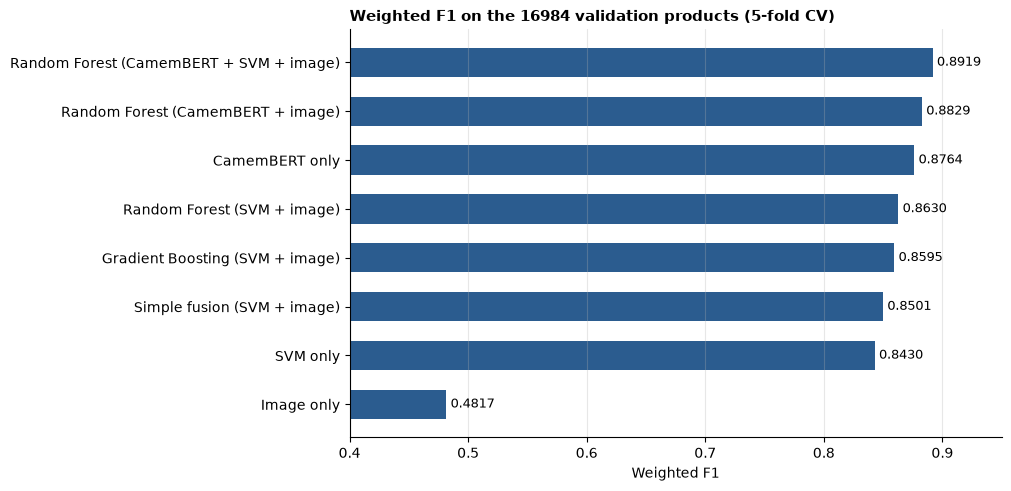

Model,Weighted F1,Macro F1
Random Forest (CamemBERT + SVM + image),0.8919,0.8785
Random Forest (CamemBERT + image),0.8829,0.8682
CamemBERT only,0.8764,0.8605
Random Forest (SVM + image),0.8630,0.8491
Gradient Boosting (SVM + image),0.8595,0.8454
Simple fusion (SVM + image),0.8501,0.8401
SVM only,0.8430,0.8326
Image only,0.4817,0.4230


In [5]:
camembert = pd.read_csv("../data/processed/camembert_validation_probabilities.csv")
camembert = both[["row_id"]].merge(camembert, on="row_id")
P_camembert = camembert[[str(c) for c in classes]].to_numpy()
predictions["CamemBERT only"] = classes[P_camembert.argmax(axis=1)]

inputs = {
    "Random Forest (CamemBERT + image)": np.hstack([P_camembert, P_image]),
    "Random Forest (CamemBERT + SVM + image)": np.hstack([P_camembert, P_text, P_image]),
}
for name, X_input in inputs.items():
    predictions[name] = np.zeros_like(y_true)
    for train_idx, test_idx in folds.split(X_input, y_true):
        forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42)
        predictions[name][test_idx] = forest.fit(X_input[train_idx], y_true[train_idx]).predict(X_input[test_idx])

all_models = [
    "Image only", "Text only", "CamemBERT only", "Simple fusion", "Gradient Boosting", "Random Forest",
    "Random Forest (CamemBERT + image)", "Random Forest (CamemBERT + SVM + image)",
]
labels = {
    "Text only": "SVM only",
    "Simple fusion": "Simple fusion (SVM + image)",
    "Gradient Boosting": "Gradient Boosting (SVM + image)",
    "Random Forest": "Random Forest (SVM + image)",
}
final = pd.DataFrame({
    "Model": [labels.get(m, m) for m in all_models],
    "Weighted F1": [f1_score(y_true, predictions[m], average="weighted") for m in all_models],
    "Macro F1": [f1_score(y_true, predictions[m], average="macro") for m in all_models],
}).sort_values("Weighted F1")

fig, ax = plt.subplots(figsize=(10, 4.8), constrained_layout=True)
bars = ax.barh(final["Model"], final["Weighted F1"], color="#2b5c8f", height=0.6)
ax.bar_label(bars, labels=[f"{v:.4f}" for v in final["Weighted F1"]], padding=3, fontsize=9)
ax.set_xlim(0.4, 0.95)
ax.set_title("Weighted F1 on the 16984 validation products (5-fold CV)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Weighted F1")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.show()

final.sort_values("Weighted F1", ascending=False).style.hide(axis="index").format(precision=4)

### Analysis

- Adding CamemBERT gives the best results.
- **Best model: Random Forest on CamemBERT + SVM + image, with 0.8919 weighted F1** and 0.8785 macro F1.
- That is +1.5 points over CamemBERT alone (0.8764) and +4.9 points over the SVM alone (0.8430).
- The SVM still adds value next to CamemBERT (0.8919 against 0.8829 without it). The two text models make different errors: CamemBERT reads context, the SVM catches rare specific words.
- The image adds about 0.7 points on top of CamemBERT alone (0.8829 against 0.8764). It helps less than with the SVM, because CamemBERT already fixes many book errors.

## Conclusion

- Combining models always helps, and a learned combination (Random Forest) works better than a fixed weight.
- Best model: Random Forest on the CamemBERT, SVM and image probabilities, with 0.8919 weighted F1 on the validation products (5-fold CV).
- Each part adds something: CamemBERT gives the best text understanding, the SVM catches rare specific words, and the image helps on books.